# Measurement-induced phase transition: a tour

Picture a quantum computer running a random circuit with random local unitary gates and random measurements, and look at the two extreme scenarios

- **No measurements.** The whole circuit is one big unitary matrix, and a random one. It entangles every qubit with every other, so any group of qubits (up to half the system) is close to maximally entangled with the rest.
- **Every qubit measured after every step.** Each measurement collapses its qubit, so the state ends as a product state: a string of 0s and 1s, with no entanglement and no more structure than the initial state $|00\cdots0\rangle$.

In between, random gates and random measurements compete. At a critical measurement rate $p_c$ the entanglement changes character abruptly: this is the *measurement-induced phase transition* (MIPT). For background, see the review by [Fisher, Khemani, Nahum & Vijay, arXiv:2207.14280](https://arxiv.org/abs/2207.14280) (Annu. Rev. Condens. Matter Phys. 14, 335 (2023)).

This notebook shows:

1. the circuits we sample,
2. the two ends of the phase diagram, simulated,
3. the half-chain entanglement entropy across the transition (**area law versus volume law**),
4. **entanglement-weighted graphs** ([Lyu et al., arXiv:2602.04969](https://arxiv.org/abs/2602.04969)): which measurement patterns in spacetime produce entanglement between two distant pairs of qubits,
5. how entanglement between distant regions decays at the critical point, from the same paper.

All simulations use `mipt_sim`, a dense state-vector simulator in NumPy. Heavy runs are done by the scripts in `scripts/` and loaded here from `results/`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import MaxNLocator

from mipt_sim import random_circuit, run_circuit
from mipt_sim.ewg import symmetrized_graph

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

## 1. The circuit

A ring of *L* qubits starts in $|00\cdots0\rangle$. Each time step has two parts:

- **Gates.** Two-qubit gates act on neighbouring pairs in a brickwork pattern: pairs (0,1), (2,3), … on even steps and (1,2), (3,4), …, (L−1, 0) on odd steps. The chain is **periodic**, so the last qubit couples back to the first. Each gate is an independent random unitary drawn from the [Haar measure](https://en.wikipedia.org/wiki/Haar_measure) on U(4), the "most random" two-qubit gate.
- **Measurements.** Each qubit is then measured in the computational basis with probability *p*. The outcome is random, drawn with the Born rule, and the state collapses accordingly.

One such random circuit, with its random measurement locations, is a *circuit realization*. Running it once, with random measurement outcomes, is a *trajectory*. Below is one realization for L = 6 over four time steps, drawn with PennyLane's `qml.draw_mpl` (wires are labelled from 0 here). The tall box spanning all wires is the gate that closes the ring on qubits 5 and 0: it acts only on those two, at the tabs.

Matplotlib is building the font cache; this may take a moment.


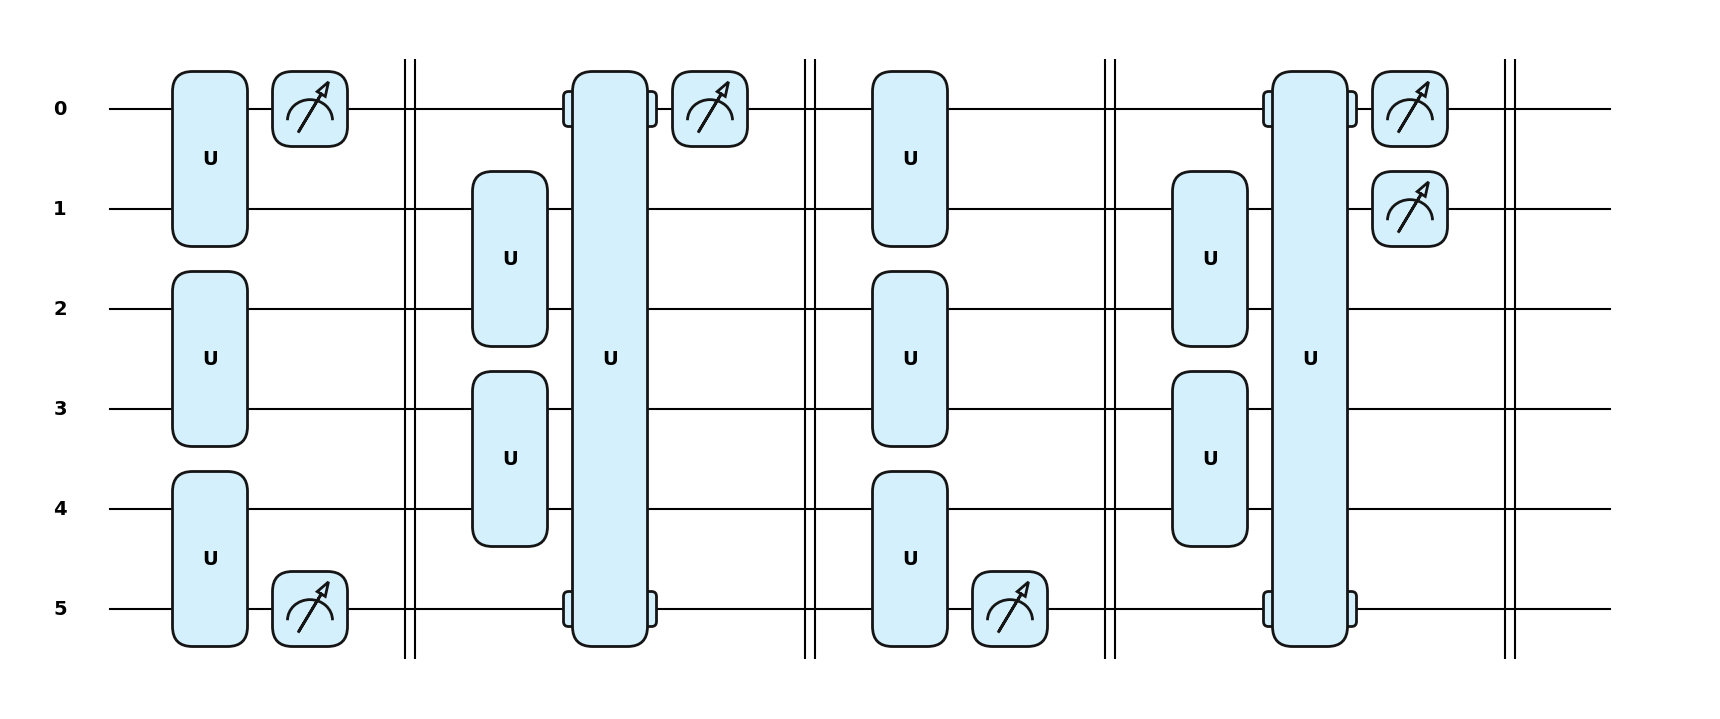

In [2]:
import pennylane as qml

L_demo = 6
layers = random_circuit(L_demo, 0.25, np.random.default_rng(3), depth=4)


def demo_circuit():
    for gates, measured in layers:
        for wires, u in gates:
            qml.QubitUnitary(u, wires=wires)
        for q in measured:
            qml.measure(q)
        qml.Barrier(wires=range(L_demo), only_visual=True)


fig, ax = qml.draw_mpl(demo_circuit, wire_order=range(L_demo), style="pennylane")()

## 2. The two ends of the phase diagram

We run one trajectory at L = 14 for 28 time steps at each end, *p* = 0 and *p* = 1. Then we compute the entanglement entropy *S* (in bits; defined in Section 3) of the first $\ell$ qubits, for every $\ell$ up to half the ring.

For comparison, the dashed line is [Page's formula](https://arxiv.org/abs/gr-qc/9305007) (Phys. Rev. Lett. 71, 1291 (1993)) for a *uniformly random* state of the whole register, which is what a large random unitary applied to $|00\cdots0\rangle$ produces on average. It sits just below the maximum $S = \ell$.

p = 1: number of nonzero amplitudes = 1


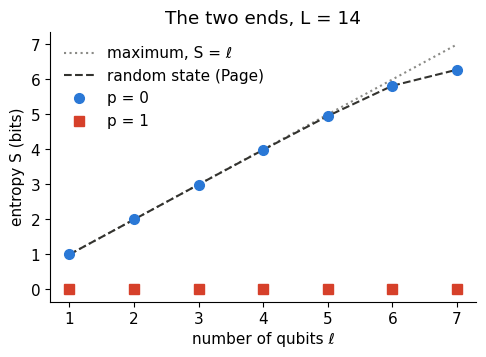

In [10]:
from mipt_sim import region_entropy


def page(l, n):  # average entropy (bits) of l qubits in a Haar-random state of n qubits
    m, k = 2**l, 2 ** (n - l)
    return (sum(1 / j for j in range(k + 1, m * k + 1)) - (m - 1) / (2 * k)) / np.log(2)


L, depth = 14, 28
ells = range(1, L // 2 + 1)
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(ells, ells, ls=":", color="#8a8a86", label="maximum, S = ℓ")
ax.plot(ells, [page(l, L) for l in ells], ls="--", color="#33332f", label="random state (Page)")
for p, c, mk in [(0.0, "#2a78d6", "o"), (1.0, "#d6402a", "s")]:
    rng = np.random.default_rng(0)
    psi = run_circuit(L, random_circuit(L, p, rng, depth), rng)
    ax.plot(ells, [region_entropy(psi, range(l)) for l in ells], mk, color=c, ms=7, label=f"p = {p:g}")
    if p == 1:
        print("p = 1: number of nonzero amplitudes =", int((np.abs(psi) > 1e-12).sum()))
ax.set(xlabel="number of qubits ℓ", ylabel="entropy S (bits)", title=f"The two ends, L = {L}")
ax.legend(frameon=False);

At *p* = 0 the entropy follows the random-state curve, growing with the number of qubits: a volume law. At *p* = 1 it is zero for every subsystem, and the final state has a single nonzero amplitude, one basis string such as $|0110\cdots\rangle$. The interesting physics lies between these ends.

## 3. Area law versus volume law

Cut the ring into two halves and ask how entangled they are. The [von Neumann entropy](https://en.wikipedia.org/wiki/Von_Neumann_entropy) *S* of one half counts this in bits: a product state has *S* = 0, and a maximally entangled half of *L*/2 qubits has *S* = *L*/2.

- With **few measurements**, the gates win: *S* grows in proportion to the size of the half, a **volume law**.
- With **many measurements**, the measurements win: *S* stays bounded however large the system, an **area law** (in one dimension the "area" of a cut is just its two end points).

For random Haar gates on qubits, the transition sits near $p_c \approx 0.17$ ([Zabalo et al., arXiv:1911.00008](https://arxiv.org/abs/1911.00008), Phys. Rev. B 101, 060301 (2020)). First, two single trajectories at L = 14: the entropy grows from zero and saturates within a few time steps, at very different levels.

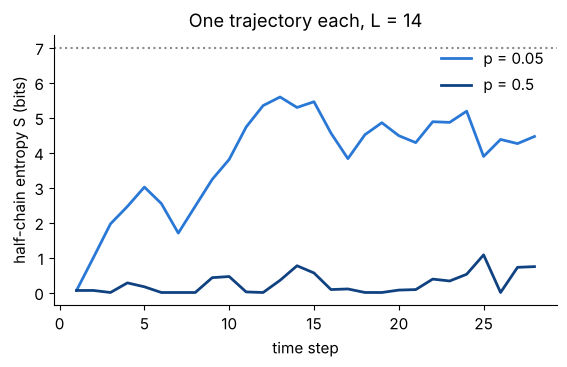

In [4]:
L, depth = 14, 28
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for p, c in [(0.05, "#2a78d6"), (0.5, "#104281")]:
    rng = np.random.default_rng(1)
    _, s = run_circuit(L, random_circuit(L, p, rng, depth), rng, record=True)
    ax.plot(range(1, depth + 1), s, color=c, lw=2, label=f"p = {p}")
ax.axhline(L / 2, ls=":", color="#8a8a86")
ax.set(xlabel="time step", ylabel="half-chain entropy S (bits)", title=f"One trajectory each, L = {L}")
ax.legend(frameon=False);

Averaging many trajectories for several sizes and rates (`scripts/sweep.py`, 40 to 800 trajectories per point, depth 2L) gives the main result. The entropy is also averaged over two neighbouring cut positions, because at large *p* it depends on whether the last layer of gates crossed the cut.

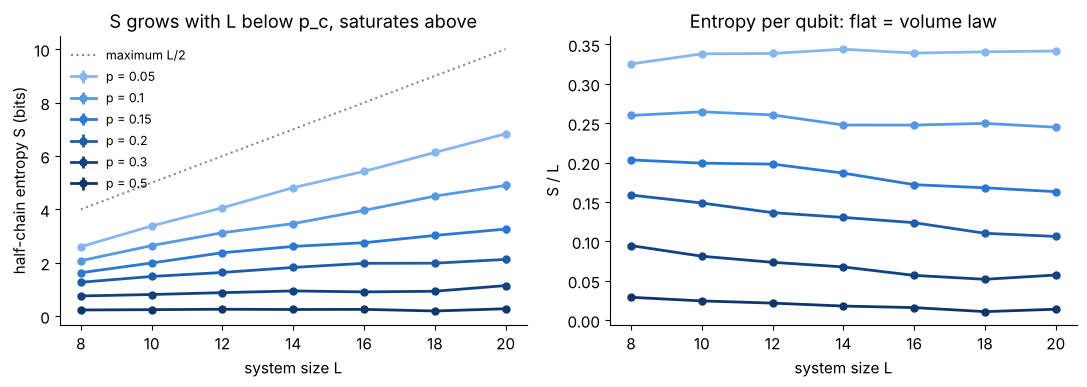

In [5]:
with open("../results/sweep.json") as f:
    rows = json.load(f)
ps = sorted({r["p"] for r in rows})
blues = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]  # light = few measurements

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
Ls = sorted({r["L"] for r in rows})
a.plot(Ls, [x / 2 for x in Ls], ls=":", color="#8a8a86", label="maximum L/2")
for p, c in zip(ps, blues):
    d = sorted((r for r in rows if r["p"] == p), key=lambda r: r["L"])
    x, y, e = [r["L"] for r in d], [r["mean"] for r in d], [r["sem"] for r in d]
    a.errorbar(x, y, e, color=c, lw=2, marker="o", ms=5, label=f"p = {p:g}")
    b.plot(x, np.array(y) / np.array(x), color=c, lw=2, marker="o", ms=5)
a.set(xlabel="system size L", ylabel="half-chain entropy S (bits)", title="S grows with L below p_c, saturates above")
b.set(xlabel="system size L", ylabel="S / L", title="Entropy per qubit: flat = volume law")
a.legend(frameon=False, fontsize=9)
plt.tight_layout();

At *p* = 0.05 and 0.1 the entropy grows linearly with *L* (constant *S*/*L*): volume law. At *p* = 0.3 and 0.5 it is flat: area law. At *p* = 0.15 and 0.2, close to $p_c \approx 0.17$, it grows slowly, as expected near the critical point, where *S* grows like log *L*. Locating $p_c$ precisely needs larger sizes and a finite-size scaling analysis.

## 4. Entanglement-weighted graphs

At the critical point, two distant regions are *usually* not entangled at all. When they are, it is because the random measurements happened to fall in a favourable pattern. An **entanglement-weighted graph** (EWG) ([Lyu et al., arXiv:2602.04969](https://arxiv.org/abs/2602.04969), Sec. III B) shows that pattern on average. For every trajectory $\varepsilon$ we keep its measurement record $W_\varepsilon(x, t)$, equal to 1 if qubit *x* was measured at time *t* and 0 otherwise, and the entanglement $E(\varepsilon)$ it produced between regions *A* and *B* at the end. The graph is the entanglement-weighted average of the records,

$$
W[E](x, t) = \frac{\sum_\varepsilon E(\varepsilon)\, W_\varepsilon(x, t)}{\sum_\varepsilon E(\varepsilon)} .
$$

Where the measurements do not matter, this equals the bare rate *p* (white). Blue marks places measured *less* often than usual in the circuits that produced entanglement; red marks places measured *more* often.

Here L = 18 and p = 0.17. The regions are the pairs *A* = qubits (1, 2) and *B* = qubits (8, 9), counting from 1. The weight *E* is the [negativity](https://en.wikipedia.org/wiki/Negativity_(quantum_mechanics)) between *A* and *B*, computed with `medt`. The plot shows the last 20 of the 36 time steps; earlier steps sit at *p* within noise. The 261,500 trajectories come from `scripts/ewg_run.py`, which stores every measurement record and its seed, so any trajectory can be replayed.

Every simulated circuit has 36 layers, so all of them end on the same brickwork parity: in the last layer B = (8, 9) shares a gate, while A's qubits are paired with sites 18 and 3. The graph should average over circuits ending on even and odd layers half-half. We get that exactly by also counting each trajectory mirrored, $x \to 10 - x$ (mod 18, 1-based), which swaps A and B and the two layer parities. Haar gates are unchanged by swapping their two qubits and the negativity is symmetric in A and B, so a mirrored trajectory is an exact sample of the circuit with the other parity (`mipt_sim.ewg.symmetrized_graph`).

In [6]:
d = np.load("../results/ewg_L18_p0.17.npz")
rec, p, L = d["records"], float(d["p"]), int(d["L"])
A, B = list(d["A"]), list(d["B"])
neg = d["negativity"]
print(f"{len(neg)} trajectories; negativity > 0 in {(neg > 1e-10).sum()} of them ({(neg > 1e-10).mean():.1%})")
print(f"mean negativity {neg.mean():.2e}")

261500 trajectories; negativity > 0 in 15514 of them (5.9%)
mean negativity 7.98e-04


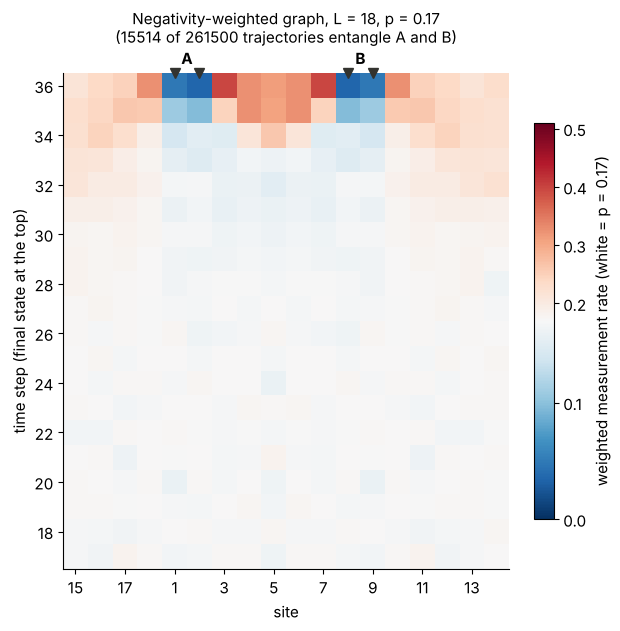

In [7]:
def plot_ewg(d, layers=20, ax=None):
    rec, p, L = d["records"], float(d["p"]), int(d["L"])
    A, B = list(d["A"]), list(d["B"])
    g = symmetrized_graph(rec, d["negativity"], A, B)[-layers:]  # even/odd final layers half-half
    t0 = len(rec[0]) - layers  # time steps shown: t0 + 1 ... depth
    shift = (L - 1 - A[0] - B[-1]) // 2  # roll the ring so A and B sit in the middle
    cols = (np.arange(L) - shift) % L
    if ax is None:
        _, ax = plt.subplots(figsize=(6.2, 6.2), constrained_layout=True)
    norm = TwoSlopeNorm(vcenter=p, vmin=0.0, vmax=3 * p)  # values above 3p saturate
    im = ax.imshow(
        np.roll(g, shift, axis=1),
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        aspect="equal",
        extent=(0.5, L + 0.5, t0 + 0.5, t0 + layers + 0.5),
    )
    ax.set_xticks(range(1, L + 1, 2), [str(cols[i] + 1) for i in range(0, L, 2)])
    ax.set_xlabel("site")
    ax.set_ylabel("time step (final state at the top)")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    top = t0 + layers + 0.5
    for q, lab in [(A, "A"), (B, "B")]:
        q = [(x + shift) % L for x in q]
        ax.annotate(
            lab,
            ((q[0] + q[-1]) / 2 + 1, top),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontweight="bold",
            annotation_clip=False,
        )
        for x in q:
            ax.plot([x + 1], [top], marker="v", color="#33332f", ms=7, clip_on=False)
    ax.set_xlim(0.5, L + 0.5)
    ax.set_ylim(t0 + 0.5, top)
    n_neg = int((d["negativity"] > 1e-10).sum())
    ax.set_title(
        f"Negativity-weighted graph, L = {L}, p = {p:g}\n({n_neg} of {len(rec)} trajectories entangle A and B)",
        pad=22,
        fontsize=11,
    )
    plt.colorbar(im, ax=ax, shrink=0.8, label=f"weighted measurement rate (white = p = {p:g})")
    return ax


plot_ewg(d, layers=20);

What the 261,500 trajectories show (about 15,500 of them have nonzero negativity; a bootstrap gives an uncertainty of about ±0.006 per cell):

- **A and B themselves are rarely measured at the end** (rate about 0.05 against p = 0.17 in the last layer). That is expected: measuring a qubit of A or B just before the end destroys its entanglement.
- **The qubits between A and B are measured *more* often in the last two layers**, about 0.3 against 0.17, up to 0.40 for sites 3 and 7, which share the final gates with A and B. A plausible reading is **entanglement swapping**: measuring the qubits that mediate the correlation can transfer their entanglement onto A and B.
- **A low-measurement bulk joins A and B.** Below those last two layers, at time steps 29 to 34, the region between A and B is measured *less* than average (about 0.16, a deficit of several standard errors once averaged over the region). Entanglement between A and B needs an unmeasured patch of spacetime connecting them, as in the paper's Fig. 6.
- **A red halo surrounds it.** The far side of the ring (sites 11 to 17) is measured more often, about 0.18 to 0.24, over the last eight time steps. Measuring there cuts A and B off from the rest of the chain, so their entanglement is not shared away.
- **Deeper in the past the graph returns to p** (0.170 on average for time steps 1 to 20). The memory of the measurement pattern reaches back about eight time steps.

The paper uses Mølmer–Sørensen gates rather than Haar gates, yet both show the same bulk-and-halo structure. With 20,000 trajectories the bulk was hidden in the noise; it took about 260,000 to see it clearly.

## 5. How entanglement decays with distance

The figure below is Fig. 4(b) of [Lyu et al., arXiv:2602.04969](https://arxiv.org/abs/2602.04969). It shows, at the critical point, how the genuine multiparty negativity between *k* distant regions falls off with their separation *d*, for *k* = 2 (red), 3 (blue) and 4 (purple) parties and sizes L = 18 to 26 (light to dark). It decays as a steep power law, about $d^{-8.8}$ for two parties, and faster for more parties. That steep decay is why the negativity above was zero in most trajectories.

One difference to keep in mind: the paper uses a trapped-ion gate set ([Mølmer–Sørensen](https://en.wikipedia.org/wiki/M%C3%B8lmer%E2%80%93S%C3%B8rensen_gate) gates dressed with random single-qubit rotations) rather than Haar-random gates. Both have their transition near *p* = 0.17.

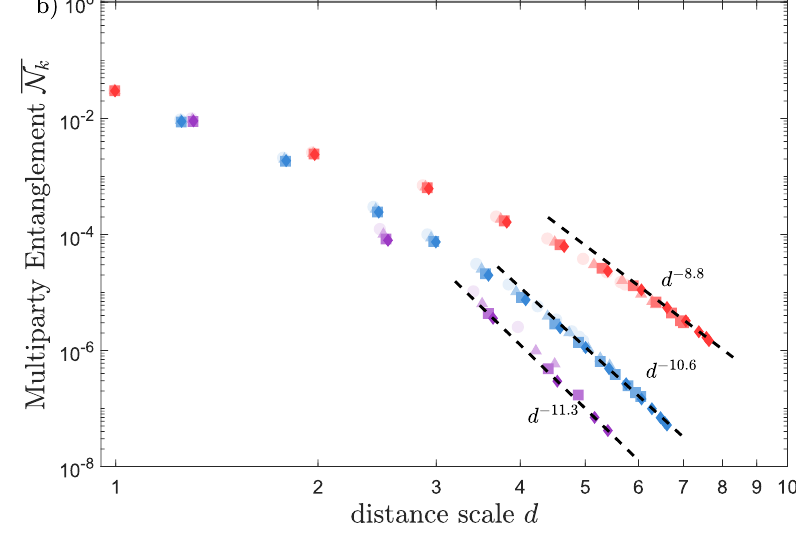

In [8]:
Image("figures/fig4b_arXiv2602.04969.png", width=560)

## Notes

- **Simulator.** `mipt_sim.numpy_sim` stores the state as a `(2,)*L` tensor and applies each gate with one `np.tensordot`. A trajectory at L = 20 takes about 2.5 s on one core of a laptop-class CPU.
- **PennyLane.** Besides drawing the circuit, PennyLane checks the simulator: `mipt_sim.pennylane_check.circuit_qnode` builds the same monitored circuit with `qml.measure`, and the tests compare our trajectory averages with PennyLane's exact outcome-averaged values. PennyLane cannot run this study by itself, because in exact mode it never returns the post-measurement state of a single trajectory (see the README).